# Restaurant Market Intelligence Platform — Market Analysis

This notebook is the analytical layer of the project. It reads the Gold tables produced by
`src/build_local_gold.py` and answers the business questions that drive the Power BI report:

1. What does the Bangalore restaurant market look like?
2. Which localities combine quality, engagement and manageable density?
3. Which cuisines are crowded versus high-performing?
4. How does price band relate to observed ratings?
5. How do online ordering and table booking relate to ratings?
6. Which locality-cuisine-price segments are worth validating for expansion?

**Scope note:** the source is one historical Zomato Bangalore snapshot with no date field.
Everything here is descriptive and associative. It does not support causal, revenue, growth or
forecasting claims.

In [1]:
from pathlib import Path
import json

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except Exception:
    plt.style.use("ggplot")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

def find_gold_dir() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / "data" / "gold"
        if (candidate / "model_features.csv").exists():
            return candidate
    raise FileNotFoundError("Could not locate data/gold. Run src/build_local_gold.py first.")

GOLD = find_gold_dir()
FIGURES = GOLD.parent.parent / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

restaurants = pd.read_csv(GOLD / "model_features.csv")
restaurants["is_high_rated"] = restaurants["is_high_rated"].astype(str).str.lower().eq("true")
restaurants["price_band"] = pd.cut(
    restaurants["cost_for_two"],
    bins=[0, 400, 800, float("inf")],
    labels=["Budget", "Mid-range", "Premium"],
    right=False,
).astype(str)

bridge = pd.read_csv(GOLD / "bridge_restaurant_cuisine.csv")
dim_cuisine = pd.read_csv(GOLD / "dim_cuisine.csv")
mart = pd.read_csv(GOLD / "mart_market_opportunity.csv")
fact = pd.read_csv(GOLD / "fact_restaurant_listing.csv")

print("Gold directory:", GOLD)
print("Restaurant rows (unique):", len(restaurants))
print("Fact rows (restaurant x listing type):", len(fact))
print("Market segments:", len(mart))

Gold directory: C:\Users\23f20\Downloads\Zomato_Restaurent_Dashboard-main\Zomato_Restaurent_Dashboard-main\data\gold
Restaurant rows (unique): 9431
Fact rows (restaurant x listing type): 41357
Market segments: 4878


## 1. Market Overview

Restaurant counts use distinct restaurant keys, not raw listing rows. The raw file has
41,418 listing rows but only 9,431 unique restaurants, because a restaurant can appear under
multiple listing categories.

In [2]:
overview = pd.DataFrame(
    {
        "metric": [
            "Unique restaurants",
            "Localities",
            "Cuisines",
            "Restaurant types",
            "Average rating",
            "Median cost for two (INR)",
            "Median votes",
            "Total votes",
            "High-rated share (%)",
            "Online order share (%)",
            "Table booking share (%)",
        ],
        "value": [
            len(restaurants),
            restaurants["location_name"].nunique(),
            dim_cuisine["cuisine_name"].nunique(),
            restaurants["restaurant_type_name"].nunique(),
            round(restaurants["rating"].mean(), 2),
            round(restaurants["cost_for_two"].median(), 2),
            round(restaurants["vote_count"].median(), 2),
            int(restaurants["vote_count"].sum()),
            round(restaurants["is_high_rated"].mean() * 100, 2),
            round(restaurants["online_order_available"].mean() * 100, 2),
            round(restaurants["table_booking_available"].mean() * 100, 2),
        ],
    }
)
overview

,metric,value
0,Unique restaurants,9431.00
1,Localities,92.00
2,Cuisines,105.00
3,Restaurant types,88.00
4,Average rating,3.62
5,Median cost for two (INR),400.00
6,Median votes,51.00
7,Total votes,2247909.00
8,High-rated share (%),22.34
9,Online order share (%),61.51


## 2. Locality Intelligence

Which localities are crowded, and which combine quality with engagement?

,location_name,restaurants,avg_rating,median_cost,avg_votes,high_rated_pct
88,Whitefield,627,3.60,500.0,233.63,20.41
9,Btm,535,3.56,350.0,131.13,12.90
25,Hsr,524,3.64,400.0,216.42,21.37
54,Marathahalli,510,3.52,400.0,264.41,15.29
19,Electronic City,458,3.47,400.0,120.76,10.26
26,Indiranagar,439,3.79,500.0,572.55,41.69
32,Jp Nagar,388,3.63,400.0,228.65,23.20
2,Bannerghatta Road,355,3.47,400.0,146.57,10.99
30,Jayanagar,312,3.77,400.0,274.77,32.37
5,Bellandur,272,3.49,400.0,140.20,15.44


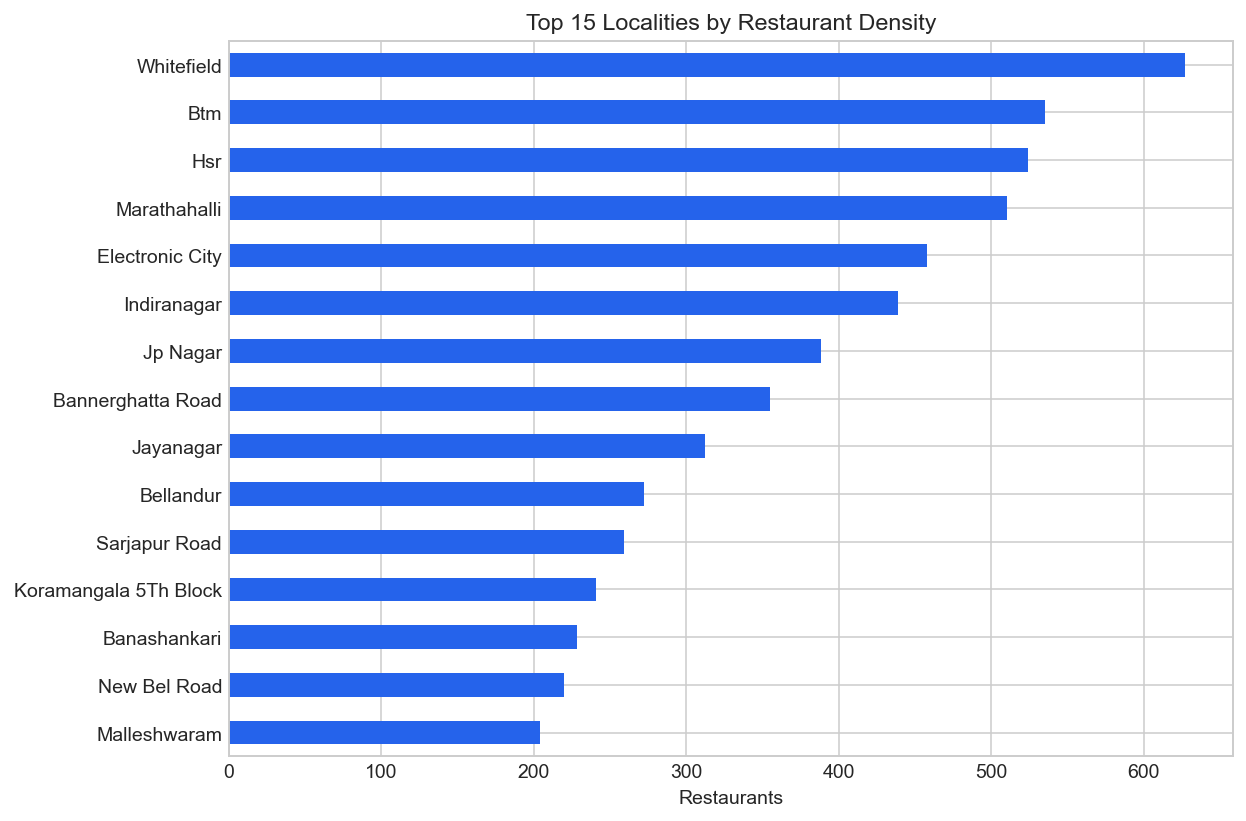

In [3]:
locality = (
    restaurants.groupby("location_name")
    .agg(
        restaurants=("restaurant_key", "nunique"),
        avg_rating=("rating", "mean"),
        median_cost=("cost_for_two", "median"),
        avg_votes=("vote_count", "mean"),
        high_rated_pct=("is_high_rated", "mean"),
    )
    .reset_index()
)
locality["high_rated_pct"] = (locality["high_rated_pct"] * 100).round(2)
locality = locality.round(2)

top_density = locality.sort_values("restaurants", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 6))
top_density.sort_values("restaurants").plot.barh(
    x="location_name", y="restaurants", ax=ax, color="#2563eb", legend=False
)
ax.set_title("Top 15 Localities by Restaurant Density")
ax.set_xlabel("Restaurants")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIGURES / "locality_density.png", dpi=170, bbox_inches="tight")
plt.show()

top_density

,location_name,restaurants,avg_rating,high_rated_pct,avg_votes
43,Koramangala 5Th Block,241,3.91,50.62,732.09
26,Indiranagar,439,3.79,41.69,572.55
30,Jayanagar,312,3.77,32.37,274.77
34,Kalyan Nagar,192,3.73,31.25,212.60
53,Malleshwaram,204,3.73,36.76,300.83
3,Basavanagudi,180,3.67,21.11,184.91


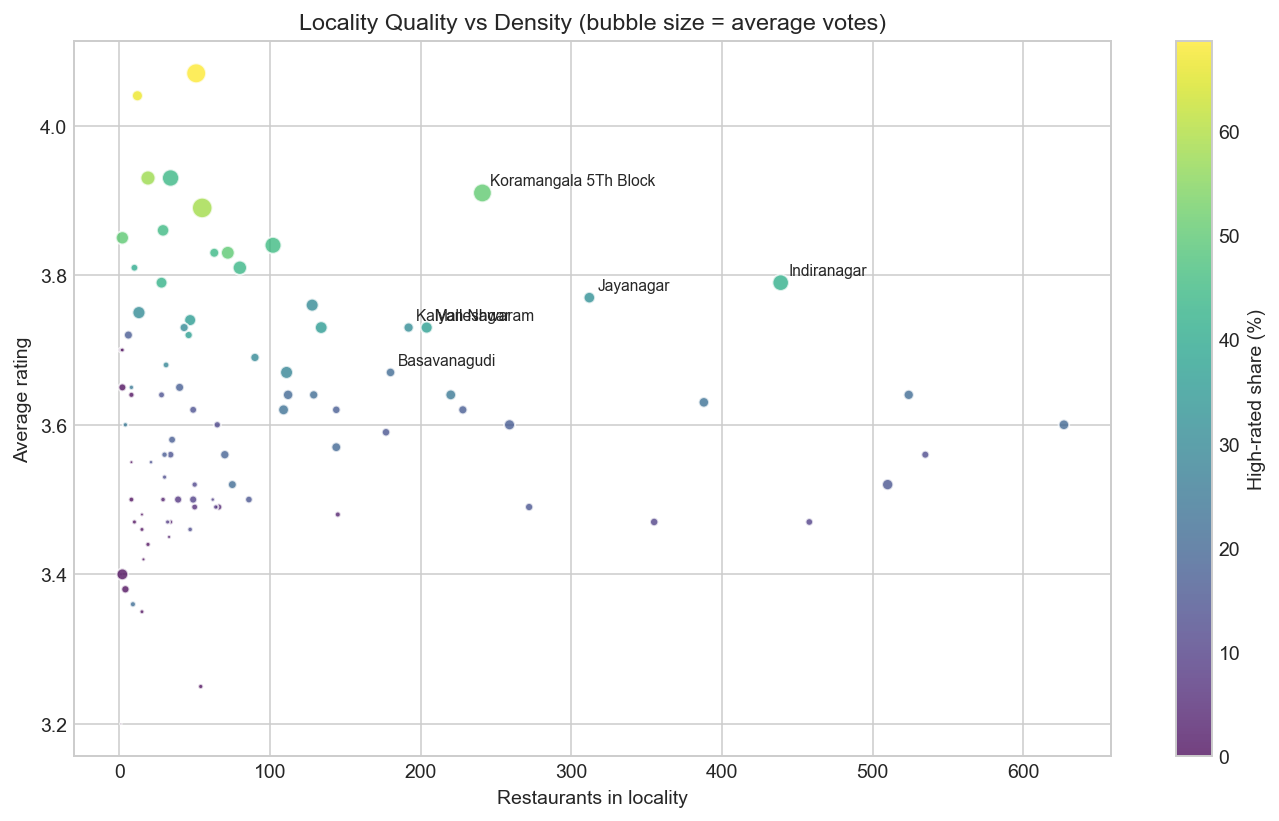

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
scatter = ax.scatter(
    locality["restaurants"],
    locality["avg_rating"],
    s=locality["avg_votes"] / 8,
    c=locality["high_rated_pct"],
    cmap="viridis",
    alpha=0.75,
    edgecolors="white",
)
ax.set_title("Locality Quality vs Density (bubble size = average votes)")
ax.set_xlabel("Restaurants in locality")
ax.set_ylabel("Average rating")
fig.colorbar(scatter, ax=ax, label="High-rated share (%)")

qualified = locality.loc[locality["restaurants"] >= 150].sort_values("avg_rating", ascending=False).head(6)
for row in qualified.itertuples():
    ax.annotate(row.location_name, (row.restaurants, row.avg_rating), fontsize=8, xytext=(4, 4), textcoords="offset points")
fig.tight_layout()
fig.savefig(FIGURES / "locality_quality_density.png", dpi=170, bbox_inches="tight")
plt.show()

qualified[["location_name", "restaurants", "avg_rating", "high_rated_pct", "avg_votes"]]

## 3. Cuisine Intelligence

Which cuisines dominate the market, and which are high-performing relative to their size?
Premium-leaning cuisines such as Japanese, Mediterranean and European carry the highest average
ratings while remaining small, which is the shape of an underserved premium niche.

,cuisine_name,restaurants,avg_rating,avg_votes,median_cost,high_rated_pct
72,North Indian,3940,3.57,279.83,500.0,18.48
27,Chinese,2915,3.54,228.76,500.0,15.64
33,Fast Food,1672,3.56,137.29,400.0,15.31
90,South Indian,1670,3.57,170.34,350.0,15.03
17,Biryani,1317,3.51,202.45,450.0,12.83
30,Desserts,1010,3.79,186.16,400.0,34.65
15,Beverages,896,3.73,179.16,400.0,28.79
29,Continental,825,3.89,634.31,900.0,47.88
23,Cafe,668,3.80,416.88,600.0,41.62
94,Street Food,624,3.59,132.41,250.0,19.55


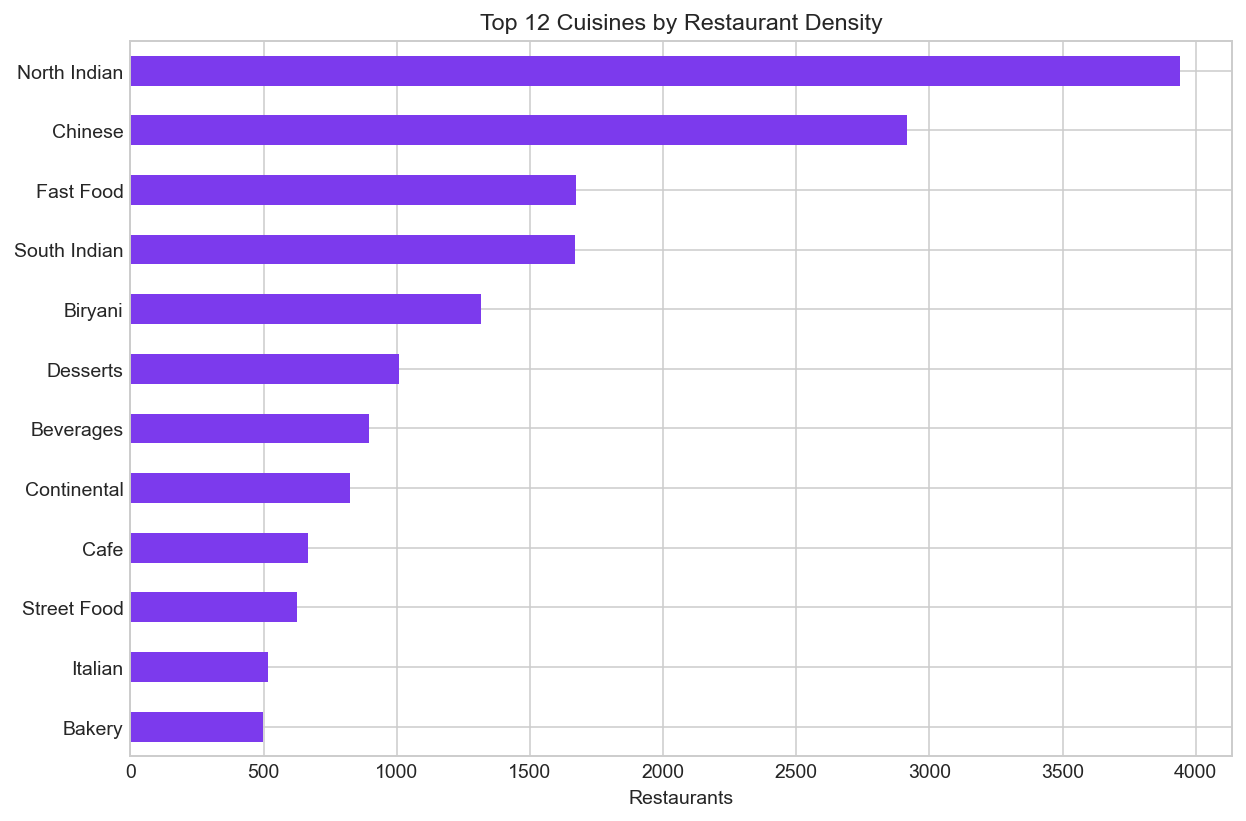

In [5]:
cuisine_frame = bridge.merge(dim_cuisine, on="cuisine_key").merge(
    restaurants[["restaurant_key", "rating", "vote_count", "cost_for_two", "is_high_rated"]],
    on="restaurant_key",
)
cuisine = (
    cuisine_frame.groupby("cuisine_name")
    .agg(
        restaurants=("restaurant_key", "nunique"),
        avg_rating=("rating", "mean"),
        avg_votes=("vote_count", "mean"),
        median_cost=("cost_for_two", "median"),
        high_rated_pct=("is_high_rated", "mean"),
    )
    .reset_index()
)
cuisine["high_rated_pct"] = (cuisine["high_rated_pct"] * 100).round(2)
cuisine = cuisine.round(2)

top_cuisine = cuisine.sort_values("restaurants", ascending=False).head(12)
fig, ax = plt.subplots(figsize=(9, 6))
top_cuisine.sort_values("restaurants").plot.barh(
    x="cuisine_name", y="restaurants", ax=ax, color="#7c3aed", legend=False
)
ax.set_title("Top 12 Cuisines by Restaurant Density")
ax.set_xlabel("Restaurants")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIGURES / "cuisine_density.png", dpi=170, bbox_inches="tight")
plt.show()

top_cuisine

,cuisine_name,restaurants,avg_rating,avg_votes,high_rated_pct
48,Japanese,45,4.21,873.58,86.67
61,Mediterranean,87,4.20,1593.37,77.01
32,European,103,4.17,1474.90,79.61
6,Asian,197,4.07,823.50,69.04
93,Steak,73,4.04,1318.89,69.86
12,Bbq,128,4.00,1296.58,53.12
103,Vietnamese,32,3.96,666.53,65.62
3,American,200,3.95,1219.48,58.00
34,Finger Food,160,3.94,830.14,55.00
62,Mexican,102,3.93,530.73,60.78


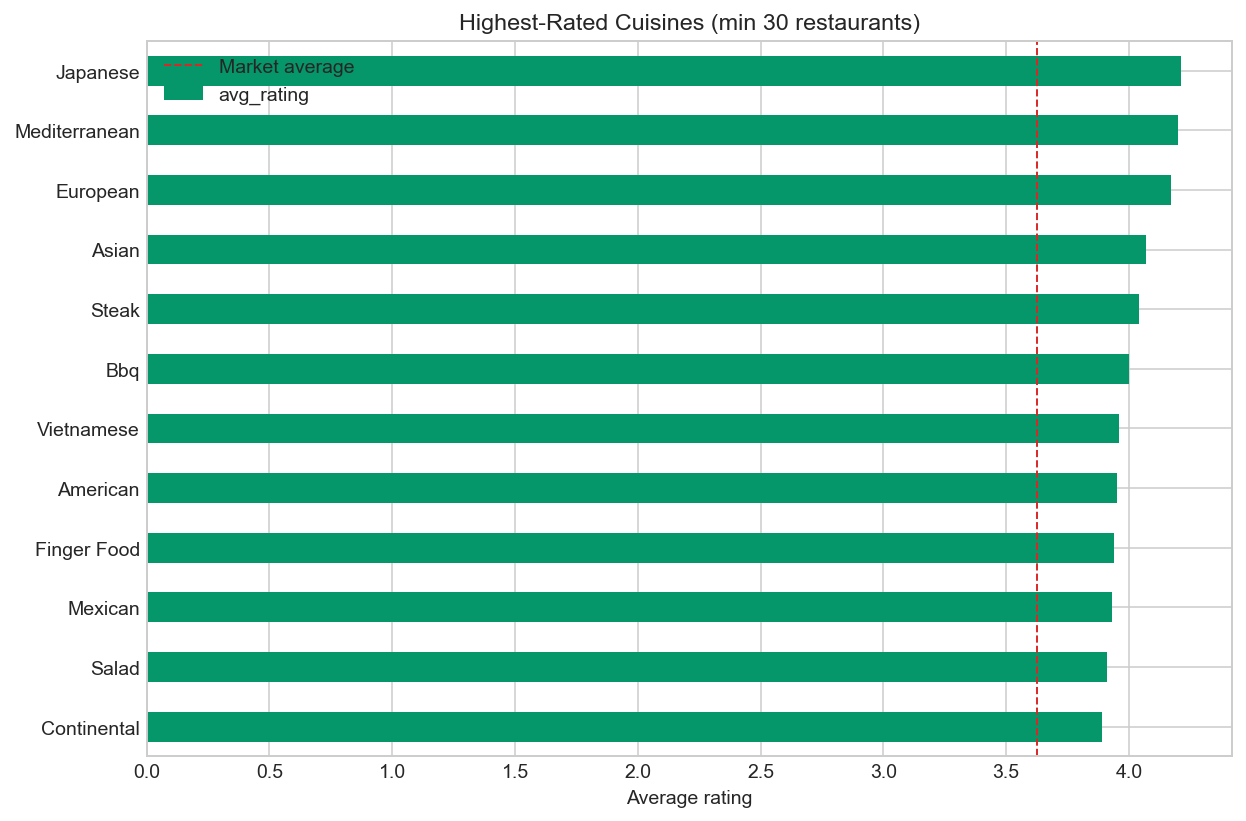

In [6]:
niche = cuisine.loc[cuisine["restaurants"] >= 30].sort_values("avg_rating", ascending=False).head(12)

fig, ax = plt.subplots(figsize=(9, 6))
niche.sort_values("avg_rating").plot.barh(
    x="cuisine_name", y="avg_rating", ax=ax, color="#059669", legend=False
)
ax.axvline(restaurants["rating"].mean(), color="#dc2626", linestyle="--", linewidth=1, label="Market average")
ax.set_title("Highest-Rated Cuisines (min 30 restaurants)")
ax.set_xlabel("Average rating")
ax.set_ylabel("")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "cuisine_rating.png", dpi=170, bbox_inches="tight")
plt.show()

niche[["cuisine_name", "restaurants", "avg_rating", "avg_votes", "high_rated_pct"]]

## 4. Pricing Strategy

Does paying more relate to better observed ratings, or is the premium segment simply different?

,price_band,restaurants,avg_rating,avg_votes,high_rated_pct,table_booking_pct
0,Budget,3624,3.54,70.07,11.51,0.22
1,Mid-range,4224,3.58,192.40,19.44,3.22
2,Premium,1583,3.93,746.23,54.90,49.65


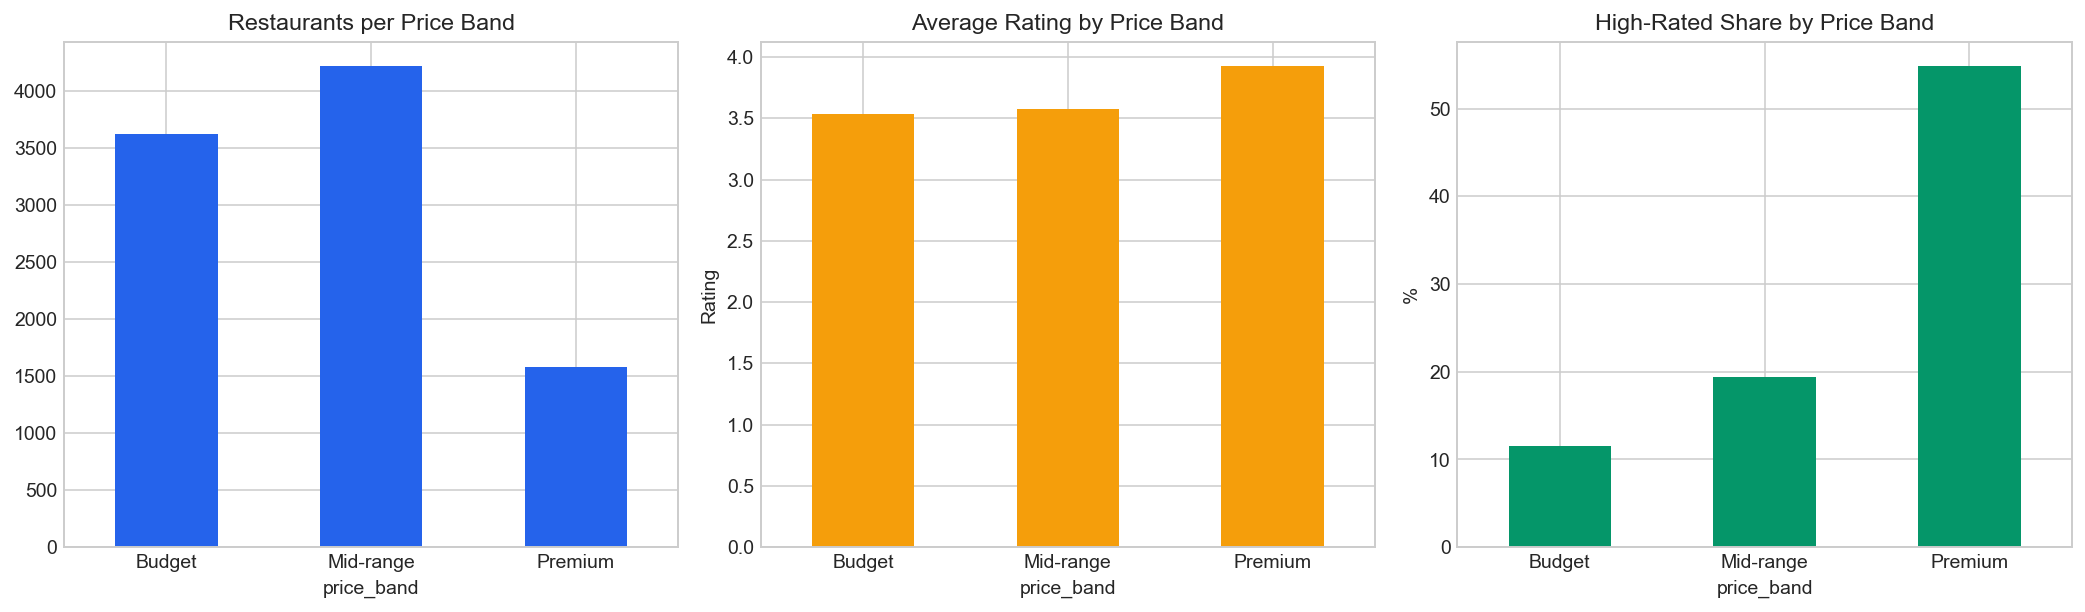

In [7]:
price = (
    restaurants.groupby("price_band")
    .agg(
        restaurants=("restaurant_key", "nunique"),
        avg_rating=("rating", "mean"),
        avg_votes=("vote_count", "mean"),
        high_rated_pct=("is_high_rated", "mean"),
        table_booking_pct=("table_booking_available", "mean"),
    )
    .reset_index()
)
for column in ["high_rated_pct", "table_booking_pct"]:
    price[column] = (price[column] * 100).round(2)
price = price.round(2).sort_values("avg_rating")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
price.set_index("price_band")["restaurants"].plot.bar(ax=axes[0], color="#2563eb", rot=0)
axes[0].set_title("Restaurants per Price Band")
axes[0].set_ylabel("")

price.set_index("price_band")["avg_rating"].plot.bar(ax=axes[1], color="#f59e0b", rot=0)
axes[1].set_title("Average Rating by Price Band")
axes[1].set_ylabel("Rating")

price.set_index("price_band")["high_rated_pct"].plot.bar(ax=axes[2], color="#059669", rot=0)
axes[2].set_title("High-Rated Share by Price Band")
axes[2].set_ylabel("%")
fig.tight_layout()
fig.savefig(FIGURES / "price_band_performance.png", dpi=170, bbox_inches="tight")
plt.show()

price

## 5. Service Availability

Online ordering and table booking are service capabilities, not quality guarantees.

,service_combo,restaurants,avg_rating,avg_votes,high_rated_pct
1,No online + No booking,3188,3.51,126.59,13.43
3,Online + No booking,5313,3.61,170.54,18.61
2,Online + Booking,488,4.08,1009.00,71.11
0,No online + Booking,442,4.15,1008.72,77.60


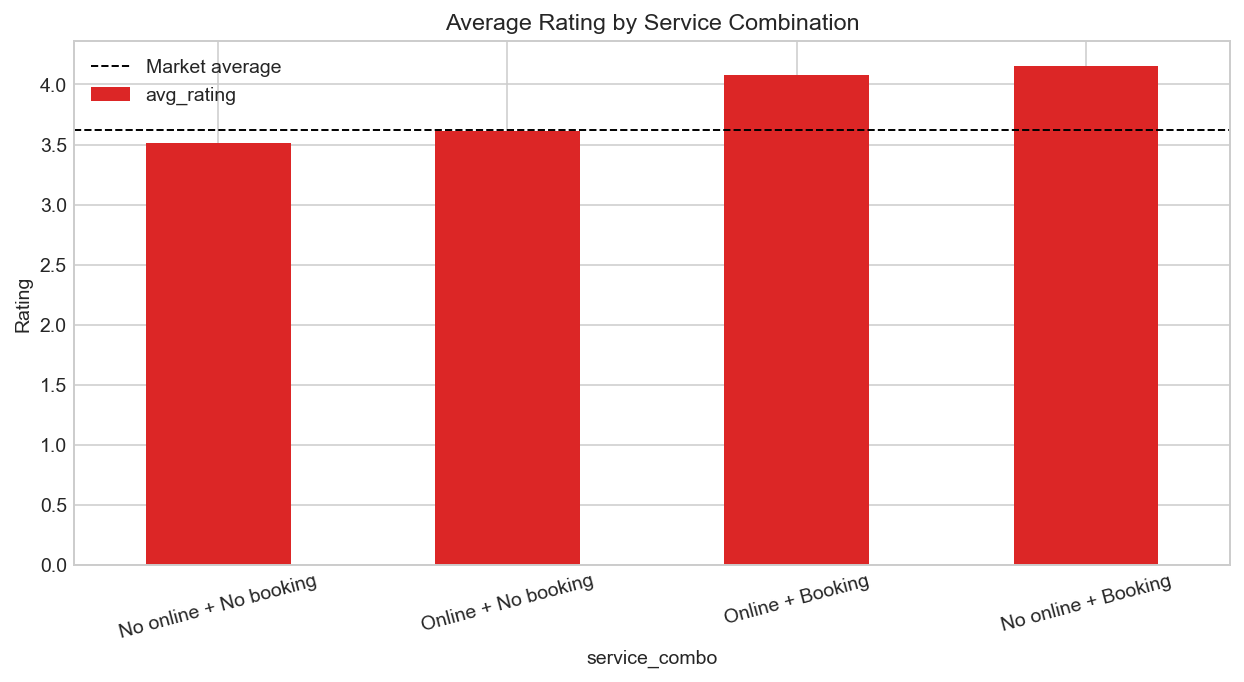

In [8]:
restaurants["service_combo"] = (
    restaurants["online_order_available"].map({True: "Online", False: "No online"})
    + " + "
    + restaurants["table_booking_available"].map({True: "Booking", False: "No booking"})
)
service = (
    restaurants.groupby("service_combo")
    .agg(
        restaurants=("restaurant_key", "nunique"),
        avg_rating=("rating", "mean"),
        avg_votes=("vote_count", "mean"),
        high_rated_pct=("is_high_rated", "mean"),
    )
    .reset_index()
)
service["high_rated_pct"] = (service["high_rated_pct"] * 100).round(2)
service = service.round(2).sort_values("avg_rating")

fig, ax = plt.subplots(figsize=(9, 5))
service.set_index("service_combo")[["avg_rating"]].plot.bar(ax=ax, color="#dc2626", legend=False, rot=15)
ax.axhline(restaurants["rating"].mean(), color="black", linestyle="--", linewidth=1, label="Market average")
ax.set_title("Average Rating by Service Combination")
ax.set_ylabel("Rating")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "service_combination.png", dpi=170, bbox_inches="tight")
plt.show()

service

## 6. Relationships Between Variables

Spearman rank correlation is used because ratings and votes are ordinal and heavily skewed.

,rating,cost_for_two,vote_count,is_high_rated
rating,1.00,0.28,0.63,0.72
cost_for_two,0.28,1.00,0.45,0.31
vote_count,0.63,0.45,1.00,0.57
is_high_rated,0.72,0.31,0.57,1.00


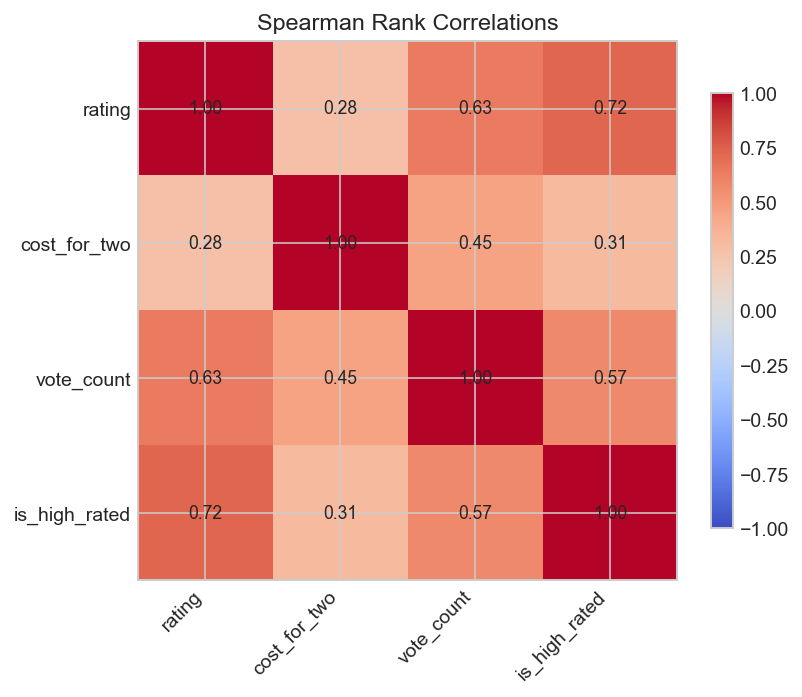

In [9]:
corr = restaurants[["rating", "cost_for_two", "vote_count", "is_high_rated"]].copy()
corr["is_high_rated"] = corr["is_high_rated"].astype(int)
spearman = corr.corr(method="spearman")

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(spearman, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(spearman.columns)))
ax.set_yticks(range(len(spearman.columns)))
ax.set_xticklabels(spearman.columns, rotation=45, ha="right")
ax.set_yticklabels(spearman.columns)
for i in range(len(spearman.columns)):
    for j in range(len(spearman.columns)):
        ax.text(j, i, f"{spearman.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Spearman Rank Correlations")
fig.colorbar(image, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(FIGURES / "correlation_matrix.png", dpi=170, bbox_inches="tight")
plt.show()

spearman.round(2)

## 7. Expansion Screening

The opportunity score is a transparent screening heuristic, not a validated recommendation:

`score = 40% demand proxy + 25% quality + 25% whitespace + 10% service fit`

It only scores locality-cuisine-price segments with at least 5 restaurants so a segment is never
ranked on a single data point.

,location_name,cuisine_name,price_band,restaurant_count,average_rating,average_votes_per_restaurant,opportunity_score,opportunity_tier
0,Church Street,Chinese,Premium,5,4.11,3143.05,94.7,Shortlist
1,Whitefield,Burger,Premium,5,4.35,958.42,92.6,Shortlist
2,Sarjapur Road,Asian,Premium,5,4.31,1560.02,92.2,Shortlist
3,Bannerghatta Road,Pizza,Premium,5,4.03,1428.08,92.0,Shortlist
4,Sarjapur Road,Finger Food,Premium,5,4.44,4098.68,91.8,Shortlist
5,Koramangala 5Th Block,Burger,Mid-range,6,4.19,1643.98,91.5,Shortlist
6,Sarjapur Road,South Indian,Premium,6,4.25,3655.45,90.9,Shortlist
7,Koramangala 3Rd Block,Cafe,Premium,5,4.23,1151.61,90.7,Shortlist
8,Koramangala 5Th Block,Salad,Premium,6,4.27,1525.23,89.7,Shortlist
9,Whitefield,Momos,Premium,6,4.36,1731.79,89.3,Shortlist


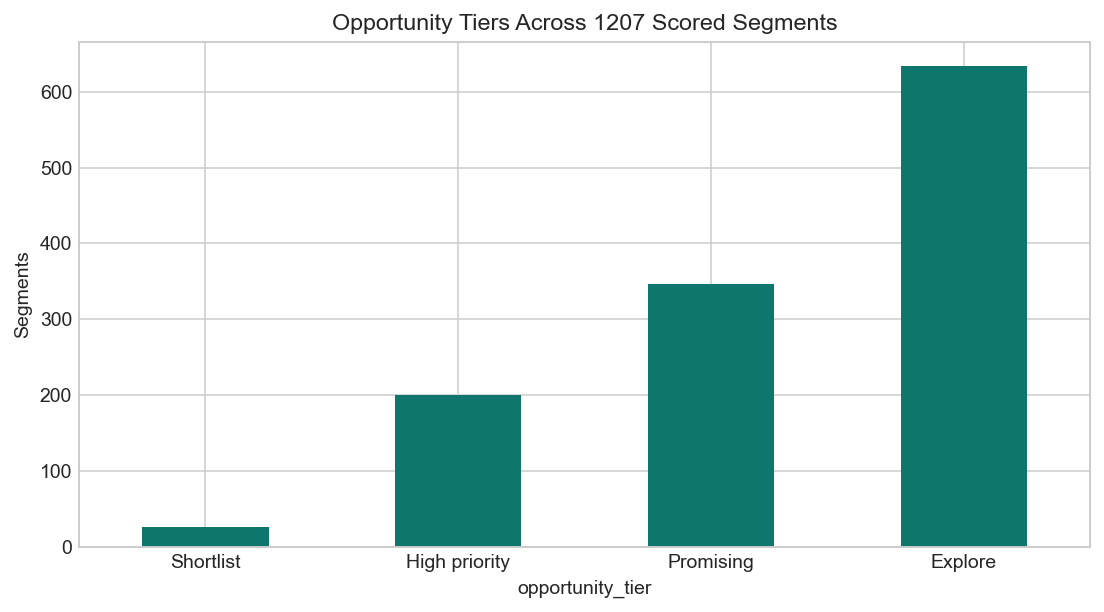

In [10]:
scored = mart.dropna(subset=["opportunity_score"]).sort_values("opportunity_score", ascending=False)
tiers = scored["opportunity_tier"].value_counts().reindex(["Shortlist", "High priority", "Promising", "Explore"])

fig, ax = plt.subplots(figsize=(8, 4.5))
tiers.plot.bar(ax=ax, color="#0f766e", rot=0)
ax.set_title(f"Opportunity Tiers Across {len(scored)} Scored Segments")
ax.set_ylabel("Segments")
fig.tight_layout()
fig.savefig(FIGURES / "opportunity_tiers.png", dpi=170, bbox_inches="tight")
plt.show()

scored.head(15)[
    [
        "location_name",
        "cuisine_name",
        "price_band",
        "restaurant_count",
        "average_rating",
        "average_votes_per_restaurant",
        "opportunity_score",
        "opportunity_tier",
    ]
]

## 8. Rating Model Summary

The classifier estimates the probability that a restaurant lands a high observed platform rating
(`rating >= 4.0` and `votes >= 20`). Votes and review text are excluded from the features so the
model does not learn the target rule or post-outcome signals.

Target: High observed rating: rating >= 4.0 and vote_count >= 20.
Selection metric: PR-AUC | Best model: random_forest


,roc_auc,pr_auc,accuracy,precision,recall,f1
logistic_regression,0.8207,0.6493,0.7689,0.4890,0.6711,0.5657
random_forest,0.8324,0.6753,0.8176,0.5898,0.6144,0.6019


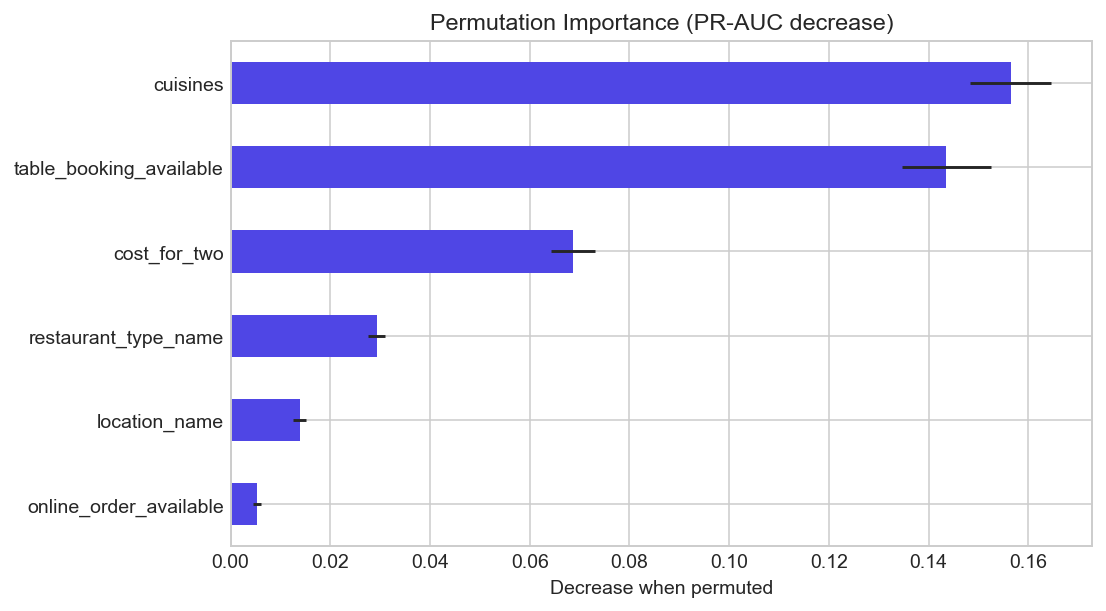

In [11]:
metrics_path = GOLD.parent.parent / "reports" / "rating_model_metrics.json"
if metrics_path.exists():
    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    comparison = pd.DataFrame(metrics["metrics"]).T
    print("Target:", metrics["target_definition"])
    print("Selection metric:", metrics["selection_metric"], "| Best model:", metrics["best_model"])
    display = comparison[["roc_auc", "pr_auc", "accuracy", "precision", "recall", "f1"]]
else:
    print("Run src/train_rating_model.py to generate reports/rating_model_metrics.json")

importance_path = GOLD.parent.parent / "reports" / "model_feature_importance.csv"
if importance_path.exists():
    importance = pd.read_csv(importance_path)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    importance.sort_values("mean_pr_auc_decrease").plot.barh(
        x="feature", y="mean_pr_auc_decrease", xerr="std_pr_auc_decrease", ax=ax,
        color="#4f46e5", legend=False
    )
    ax.set_title("Permutation Importance (PR-AUC decrease)")
    ax.set_xlabel("Decrease when permuted")
    ax.set_ylabel("")
    fig.tight_layout()
    fig.savefig(FIGURES / "model_importance_notebook.png", dpi=170, bbox_inches="tight")
    plt.show()

display

## 9. Findings

Each statement below is generated from the executed cells, so it always matches the data.

In [12]:
findings = {
    "market": (
        f"{len(restaurants):,} unique restaurants across {restaurants['location_name'].nunique()} localities "
        f"with a {round(restaurants['is_high_rated'].mean() * 100, 1)}% high-rated share."
    ),
    "density": (
        "Whitefield, BTM and HSR carry the most restaurants, so they are the most saturated markets."
    ),
    "quality": (
        "Lavelle Road, Koramangala 5th Block and Church Street combine high average ratings with strong "
        "engagement, which marks them as premium-quality pockets."
    ),
    "pricing": (
        "Premium restaurants show a far higher high-rated share than budget restaurants, but they are only "
        f"{round((price.set_index('price_band').loc['Premium', 'restaurants'] / len(restaurants)) * 100, 1)}% of the market."
    ),
    "service": (
        "Restaurants that accept table booking average clearly higher ratings than those that do not, "
        "which is an association, not proof of causation."
    ),
    "recommendation": (
        "The expansion screen shortlists premium segments such as Church Street/Chinese, Whitefield/Burger "
        "and Sarjapur Road/Asian for further validation."
    ),
}
for key, value in findings.items():
    print(f"[{key}] {value}")

[market] 9,431 unique restaurants across 92 localities with a 22.3% high-rated share.
[density] Whitefield, BTM and HSR carry the most restaurants, so they are the most saturated markets.
[quality] Lavelle Road, Koramangala 5th Block and Church Street combine high average ratings with strong engagement, which marks them as premium-quality pockets.
[pricing] Premium restaurants show a far higher high-rated share than budget restaurants, but they are only 16.8% of the market.
[service] Restaurants that accept table booking average clearly higher ratings than those that do not, which is an association, not proof of causation.
[recommendation] The expansion screen shortlists premium segments such as Church Street/Chinese, Whitefield/Burger and Sarjapur Road/Asian for further validation.
